In [1]:
# ==========================================
# Block 1 - Import and Config
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.optimize import minimize, differential_evolution
import warnings
import random
from adjustText import adjust_text
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from matplotlib.transforms import Bbox

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

In [2]:
# ==========================================
# Block 2 - Load Data
# ==========================================
multimodal_acc_df = pd.read_csv("eval_results/multimodal_accuracy.csv")
text_acc_df = pd.read_csv("eval_results/text_accuracy.csv")

# Clean column names
text_acc_df.columns = text_acc_df.columns.str.strip()
multimodal_acc_df.columns = multimodal_acc_df.columns.str.strip()

# Remove last two rows from text_acc_df
text_acc_df = text_acc_df[:-2]

# Extract model names
modelnames = text_acc_df['model_name'].tolist()

# Sort multimodal_accuracy to match model order
multimodal_acc_df['ModelName'] = multimodal_acc_df['BaseModel'].str.split('/').str[-1]
acc_filtered = (
    multimodal_acc_df[multimodal_acc_df['ModelName'].isin(modelnames)]
    .assign(order=lambda df: df['ModelName'].map({name: i for i, name in enumerate(modelnames)}))
    .sort_values('order')
    .drop(columns=['ModelName', 'order'])
    .reset_index(drop=True)
)

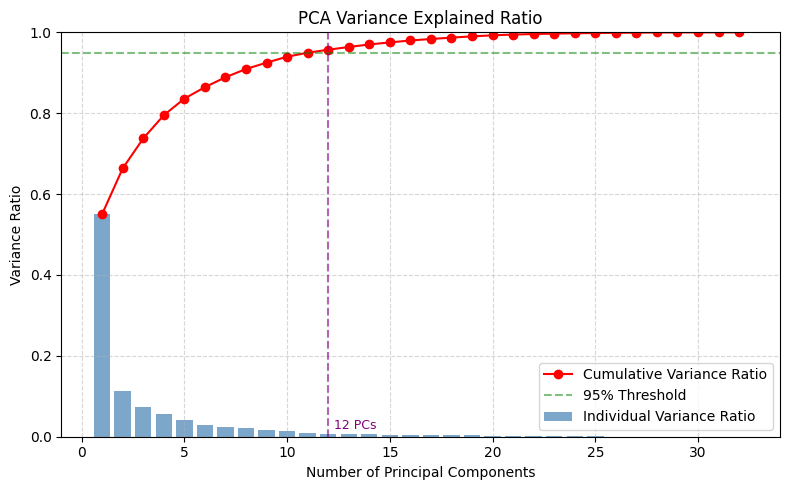

Number of PCs needed to reach 95% cumulative variance: 12


In [3]:
# ==========================================
# Block 3 - PCA Analysis
# ==========================================
class PCAAnalyzer:
    def __init__(self, data, n_components=3):
        self.data = data
        self.n_components = n_components
        self.pca = PCA(n_components=self.n_components)
        self.is_fitted = False

    def fit(self):
        self.pca.fit(self.data)
        self.is_fitted = True

    def transform(self, X_new):
        if not self.is_fitted:
            raise ValueError("PCA model must be fitted first.")
        if isinstance(X_new, pd.DataFrame):
            X_new = X_new[self.data.columns]
        return self.pca.transform(X_new)

    def get_explained_variance_ratio(self):
        ratio = self.pca.explained_variance_ratio_
        cumulative_ratio = np.cumsum(ratio)
        return pd.DataFrame({
            'Component': [f'PC{i+1}' for i in range(len(ratio))],
            'Variance Ratio': ratio,
            'Cumulative Ratio': cumulative_ratio
        })

# Fit PCA
performance_data = text_acc_df.iloc[:, 1:]
pc_num = 32
pca_analyzer = PCAAnalyzer(performance_data, n_components=pc_num)
pca_analyzer.fit()

# Transform to PC values
pc_values = pca_analyzer.transform(performance_data)
pc_columns = [f"PC{i}" for i in range(1, pc_num + 1)]
pc_values_df = pd.DataFrame(pc_values, columns=pc_columns)
pc_values_df.insert(0, 'modelname', modelnames)

# Plot variance ratio & find PC count for 95% variance
variance_df = pca_analyzer.get_explained_variance_ratio()
threshold = 0.95
pc_needed = np.argmax(variance_df['Cumulative Ratio'] >= threshold) + 1

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(variance_df)+1), variance_df['Variance Ratio'], alpha=0.7, color='steelblue', label='Individual Variance Ratio')
plt.plot(range(1, len(variance_df)+1), variance_df['Cumulative Ratio'], 'ro-', label='Cumulative Variance Ratio')
plt.axhline(y=threshold, color='g', linestyle='--', alpha=0.5, label='95% Threshold')
plt.axvline(x=pc_needed, color='purple', linestyle='--', alpha=0.6)
plt.text(pc_needed + 0.3, 0.02, f"{pc_needed} PCs", color='purple', fontsize=9)
plt.ylim(0, 1)
plt.xlabel("Number of Principal Components")
plt.ylabel("Variance Ratio")
plt.title("PCA Variance Explained Ratio")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Number of PCs needed to reach 95% cumulative variance: {pc_needed}")

In [4]:
# ==========================================
# Block 4 - Prepare Data for Scaling Law
# ==========================================
pc_name = [f"PC{i}" for i in range(1, pc_num + 1)]
df_llm = [acc_filtered.iloc[i] for i in range(len(acc_filtered))]

def get_S_D_L(df_acc, df_pc, pc_name, pc_loc):
    S_vec = [float(df_pc[name].iloc[pc_loc]) for name in pc_name]
    D_vec, L_vec = [], []
    for idx, value in df_acc.items():
        if idx == "BaseModel":
            continue
        if pd.isna(value) or value == "Error":
            continue
        step = int(idx.replace('ckpt-', ''))
        D_vec.append(step * 8192 * 512 / 1e9)
        acc = float(value.rstrip('%')) / 100 if isinstance(value, str) and '%' in value else float(value)
        L_vec.append(acc)
    return S_vec, D_vec, L_vec

n_models = len(df_llm)
S_matrix = np.zeros((n_models, len(pc_name)))
D_list, L_list = [], []
for i, item in enumerate(df_llm):
    S_vec, D_vec, L_vec = get_S_D_L(item, pc_values_df, pc_name, i)
    S_matrix[i, :] = S_vec
    D_list.append(np.array(D_vec))
    L_list.append(np.array(L_vec))

# All models used for training
n_train = n_models
D_all_np = D_list[0]
L_train_np = np.array([L_list[i] for i in range(n_train)])
S_train_list = [S_matrix[:n_train, i] for i in range(len(pc_name))]

In [5]:
# ==========================================
# Block 5 - Fit Scaling Law
# ==========================================
# 1. Define loss functions
def huber_loss(x, delta=1.0):
    """Huber loss function to reduce the impact of outliers."""
    abs_x = np.abs(x)
    return np.where(abs_x <= delta, 0.5 * x**2, delta * (abs_x - 0.5 * delta))

def fit_acc(params, S_list, D, L, alpha=1e-4):
    """
    Objective function for scaling law fitting.
    
    Parameters:
        params: list of parameters [A, B0, Bm, P0, k1, ..., k_pc_needed]
        S_list: list of numpy arrays, each containing PC values for all models
        D: numpy array of token counts
        L: numpy array of target accuracy values
        alpha: regularization coefficient for k parameters
    
    Returns:
        Scalar loss value.
    """
    A, B0, Bm, P0 = params[:4]
    k_coeffs = params[4:]
    
    # Compute combined S values using k coefficients
    S = np.zeros(S_list[0].shape[0], dtype=float)
    for k, s_data in zip(k_coeffs, S_list):
        S += k * s_data
    
    # Prevent invalid D values
    if np.any(D <= 0):
        return 1e9
    
    # Predicted accuracy
    ln_D = np.log(D)
    L_pred = (A * S[:, None] + (B0 - Bm * S[:, None]) * ln_D[None, :] + P0)
    
    # Penalty for negative absorption
    absorption = B0 - Bm * S
    penalty = 1e5 * np.sum(absorption[absorption < 0] ** 2) if np.any(absorption < 0) else 0.0
    
    # Compute residuals and apply Huber loss
    valid_mask = ~np.isnan(L)
    residual = L_pred[valid_mask] - L[valid_mask]
    loss = np.sum(huber_loss(residual)) + penalty
    
    # L2 regularization on k coefficients
    loss += alpha * np.sum(k_coeffs ** 2)
    
    return loss

# 2. Set fixed number of PCs
S_train_fit = S_train_list[:pc_needed]
args_data   = (S_train_fit, D_all_np, L_train_np)

# 3. Global search using Differential Evolution
bounds_de = [
    (0, 10.0),       # A
    (1e-6, 10.0),    # B0
    (1e-6, 10.0),    # Bm
    (-10.0, 10.0)    # P0
] + [(-50.0, 50.0)] * pc_needed

global_res = differential_evolution(
    fit_acc,
    bounds=bounds_de,
    args=args_data,
    strategy='best1bin',
    maxiter=2000,
    popsize=8,
    workers=-1,
    disp=True,
    seed=RANDOM_SEED
)

# 4. Local refinement using L-BFGS-B
bounds_local = [
    (1e-6, None),    # A
    (1e-6, None),    # B0
    (1e-6, None),    # Bm
    (None, None)     # P0
] + [(None, None)] * pc_needed

final_res = minimize(
    fit_acc,
    x0=global_res.x.copy(),
    args=args_data,
    method='L-BFGS-B',
    bounds=bounds_local,
    options={
        'maxiter': 1000000,    # Increase iteration limit
        'maxfun': 1000000,     # Increase function evaluation limit
        'disp': True           # Display optimization progress
    }
)

differential_evolution step 1: f(x)= 2520.8407194458705
differential_evolution step 2: f(x)= 1339.0370473830963
differential_evolution step 3: f(x)= 1339.0370473830963
differential_evolution step 4: f(x)= 1339.0370473830963
differential_evolution step 5: f(x)= 681.8553026325858
differential_evolution step 6: f(x)= 681.8553026325858
differential_evolution step 7: f(x)= 646.0913108546627
differential_evolution step 8: f(x)= 202.75049593711952
differential_evolution step 9: f(x)= 202.75049593711952
differential_evolution step 10: f(x)= 202.75049593711952
differential_evolution step 11: f(x)= 202.75049593711952
differential_evolution step 12: f(x)= 202.75049593711952
differential_evolution step 13: f(x)= 202.75049593711952
differential_evolution step 14: f(x)= 183.03525300430687
differential_evolution step 15: f(x)= 183.03525300430687
differential_evolution step 16: f(x)= 183.03525300430687
differential_evolution step 17: f(x)= 183.03525300430687
differential_evolution step 18: f(x)= 183.0

In [6]:
# ==========================================
# Block 6 - Output Training Results
# ==========================================
p = final_res.x
A = p[0]
B0 = p[1]
Bm = p[2]
P0 = p[3]
k_values = p[4:]

# Calculate the norm (Euclidean length) of k
k_norm = np.linalg.norm(k_values)

# Normalize k
k_normalized = k_values / k_norm

# Compute adjusted A and Bm using normalized k
A_true = A * k_norm
Bm_true = Bm * k_norm

print(f"\nOptimization status: {final_res.message}")
print(f"Final Loss: {final_res.fun:.6f}")
print(f"Adjusted A_true = {A_true:.6f}")
print(f"Adjusted Bm_true = {Bm_true:.6f}")
print(f"k norm          = {k_norm:.6f}")
print(f"k coefficients ({pc_needed} PCs) - normalized:")
for i, k_val in enumerate(k_normalized):
    end_char = '\n' if (i + 1) % 3 == 0 else ',  '
    print(f"  k{i+1:<2} = {k_val:.6f}", end=end_char)
print()

# Compute Train MAE using normalized k and adjusted A_true/Bm_true
S_final = np.zeros(L_train_np.shape[0], dtype=float)
for k, s_data in zip(k_normalized, S_train_list[:pc_needed]):
    S_final += k * s_data
L_pred_train = (A_true * S_final[:, None] + (B0 - Bm_true * S_final[:, None]) * np.log(D_all_np)[None, :] + P0)
mae_train = np.mean(np.abs(L_pred_train - L_train_np))
print(f"Train MAE: {mae_train:.6f} ({mae_train*100:.4f}%)")

# Compute absorption rate range
absorption = B0 - Bm_true * S_final
print(f"Absorption rate range: [{absorption.min():.4f}, {absorption.max():.4f}]")


Optimization status: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Final Loss: 0.032965
Adjusted A_true = 0.232955
Adjusted Bm_true = 0.008968
k norm          = 0.209155
k coefficients (12 PCs) - normalized:
  k1  = -0.358804,    k2  = 0.247462,    k3  = 0.146189
  k4  = -0.017146,    k5  = 0.012440,    k6  = -0.036570
  k7  = 0.108560,    k8  = -0.134069,    k9  = 0.124256
  k10 = -0.251839,    k11 = 0.563792,    k12 = -0.600317

Train MAE: 0.012871 (1.2871%)
Absorption rate range: [0.0112, 0.0187]


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


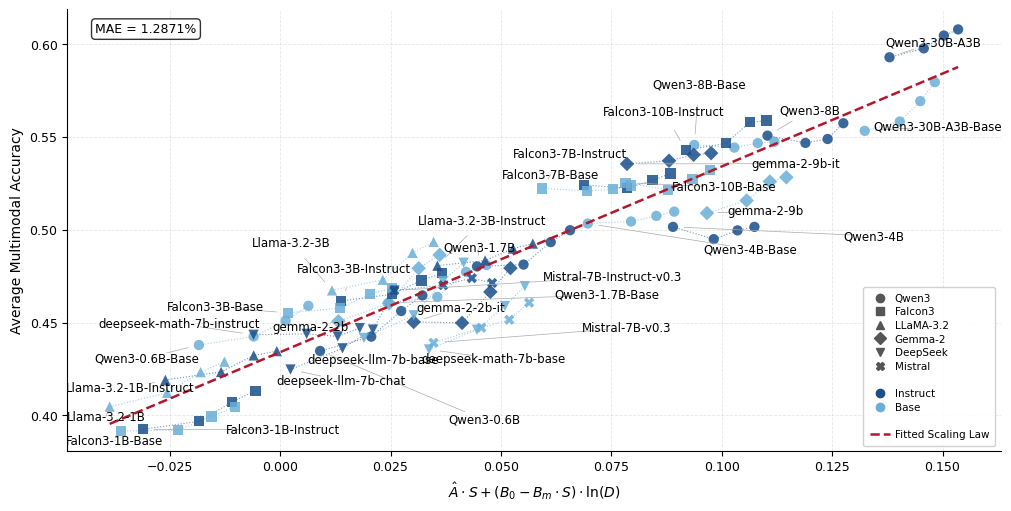

In [7]:
# ==========================================
# Block 7 - Plot Training Trajectories
# ==========================================

# Compute X-axis and Y-axis values for plotting
params        = final_res.x
A, B0, Bm, P0 = params[:4]
k_values      = params[4:]

# Use the same PCs as in fitting
S_train_fit = S_train_list[:pc_needed]
S_train = np.zeros(n_train, dtype=float)
for k, s_data in zip(k_values, S_train_fit):
    S_train += k * s_data[:n_train]

ln_D = np.log(D_all_np)
X_train = (A * S_train[:, None] + (B0 - Bm * S_train[:, None]) * ln_D[None, :])
Y_train = L_train_np

# Only use first N checkpoints for plotting
N_CKPT_PLOT = 4
X_train = X_train[:, :N_CKPT_PLOT]
Y_train = Y_train[:, :N_CKPT_PLOT]

# Model family and type mapping
model_names = [
    'Qwen3-0.6B', 'Qwen3-0.6B-Base',
    'Falcon3-1B-Instruct', 'Falcon3-1B-Base',
    'Llama-3.2-1B-Instruct', 'Llama-3.2-1B',
    'Qwen3-1.7B', 'Qwen3-1.7B-Base',
    'gemma-2-2b-it', 'gemma-2-2b',
    'Falcon3-3B-Instruct', 'Falcon3-3B-Base',
    'Llama-3.2-3B-Instruct', 'Llama-3.2-3B',
    'Qwen3-4B', 'Qwen3-4B-Base',
    'deepseek-llm-7b-chat', 'deepseek-llm-7b-base',
    'deepseek-math-7b-instruct', 'deepseek-math-7b-base',
    'Falcon3-7B-Instruct', 'Falcon3-7B-Base',
    'Mistral-7B-Instruct-v0.3', 'Mistral-7B-v0.3',
    'Qwen3-8B', 'Qwen3-8B-Base',
    'gemma-2-9b-it', 'gemma-2-9b',
    'Falcon3-10B-Instruct', 'Falcon3-10B-Base',
    'Qwen3-30B-A3B', 'Qwen3-30B-A3B-Base'
]

families = [
    'Qwen3', 'Qwen3', 'Falcon3', 'Falcon3',
    'LLaMA-3.2', 'LLaMA-3.2', 'Qwen3', 'Qwen3',
    'Gemma-2', 'Gemma-2', 'Falcon3', 'Falcon3',
    'LLaMA-3.2', 'LLaMA-3.2', 'Qwen3', 'Qwen3',
    'DeepSeek', 'DeepSeek', 'DeepSeek', 'DeepSeek',
    'Falcon3', 'Falcon3', 'Mistral', 'Mistral',
    'Qwen3', 'Qwen3', 'Gemma-2', 'Gemma-2',
    'Falcon3', 'Falcon3', 'Qwen3', 'Qwen3'
]

# Even index = chat, odd index = base
model_types = ['chat' if m_idx % 2 == 0 else 'base' for m_idx in range(n_train)]
unique_families = list(dict.fromkeys(families))

# Marker and color mapping
MARKER_MAP = {
    'Qwen3': 'o',
    'Falcon3': 's',
    'LLaMA-3.2': '^',
    'Gemma-2': 'D',
    'DeepSeek': 'v',
    'Mistral': 'X',
    'Qwen2.5'  : '*'
}
COLOR_MAP = {
    'chat': '#1a4f8a',
    'base': '#6aaed6',
    'holdout_true': '#d6604d'
}

# Figure style parameters
FIG_WIDTH   = 10.0
FIG_HEIGHT  = 5.0
FONT_SIZE   = 9
LABEL_SIZE  = 10
MARKER_SIZE = 55
LEGEND_SIZE = 7.5
LINE_WIDTH  = 1.8
MARKER_MS   = 6
ANNOT_SIZE  = 8.5

# Create figure and axis
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), constrained_layout=True)

# Scatter plot and annotation collection
texts = []
all_scatter_x = []
all_scatter_y = []

for m_idx in range(n_train):
    fam = families[m_idx]
    mtype = model_types[m_idx]
    marker = MARKER_MAP[fam]
    color = COLOR_MAP[mtype]

    x_row = X_train[m_idx]
    y_row = Y_train[m_idx]
    valid = ~np.isnan(y_row)

    # Connect points for the same model
    ax.plot(x_row[valid], y_row[valid],
            color=color, linewidth=0.8, linestyle=':', alpha=0.6, zorder=2)

    # Scatter points
    ax.scatter(x_row[valid], y_row[valid],
               marker=marker, color=color, s=MARKER_SIZE,
               alpha=0.85, edgecolors='none', zorder=3)

    all_scatter_x.extend(x_row[valid].tolist())
    all_scatter_y.extend(y_row[valid].tolist())

    # Annotate first valid point
    first_valid = np.where(valid)[0]
    if len(first_valid) > 0:
        fx = x_row[first_valid[0]]
        fy = y_row[first_valid[0]]
        t = ax.text(fx, fy, model_names[m_idx],
                    fontsize=ANNOT_SIZE, color='black',
                    va='bottom', ha='left', zorder=5)
        texts.append(t)

# Fitted scaling law line: Y = X + P0
X_flat = X_train.flatten()
Y_flat = Y_train.flatten()
valid_all = ~np.isnan(Y_flat)
x_line = np.linspace(X_flat[valid_all].min(), X_flat[valid_all].max(), 200)
y_line = x_line + P0
ax.plot(x_line, y_line, color='#B2182B', linewidth=LINE_WIDTH, linestyle='--', zorder=4)

# Adjust text positions to avoid overlap
adjust_text(
    texts,
    x=all_scatter_x, y=all_scatter_y, ax=ax,
    expand=(1.5, 1.6),
    arrowprops=dict(arrowstyle='-', color='#aaaaaa', lw=0.5, shrinkA=15, shrinkB=8),
    force_text=(0.8, 1.0),
    force_points=(0.6, 0.8),
    iter_lim=1000
)

# Legend setup
shape_handles = [
    mlines.Line2D([], [], color='#555555', marker=MARKER_MAP[fam],
                  linestyle='None', markersize=MARKER_MS, label=fam)
    for fam in unique_families
]
color_handles = [
    mlines.Line2D([], [], color=COLOR_MAP['chat'], marker='o',
                  linestyle='None', markersize=MARKER_MS, label='Instruct'),
    mlines.Line2D([], [], color=COLOR_MAP['base'], marker='o',
                  linestyle='None', markersize=MARKER_MS, label='Base')
]
fit_handle = mlines.Line2D([], [], color='#B2182B', linewidth=LINE_WIDTH,
                           linestyle='--', label='Fitted Scaling Law')
separator = Patch(color='none', label='')

ax.legend(
    handles=(shape_handles + [separator] + color_handles + [separator, fit_handle]),
    fontsize=LEGEND_SIZE, framealpha=0.9, edgecolor='#cccccc',
    loc='lower right', borderaxespad=0.5, handletextpad=0.4,
    borderpad=0.6, labelspacing=0.35
)

# Display MAE on plot
residuals = L_pred_train - L_train_np
std_train = np.std(residuals)
ax.text(0.03, 0.97, f'MAE = {mae_train*100:.4f}%',
        transform=ax.transAxes, fontsize=FONT_SIZE,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Axis labels and style
ax.set_xlabel(r'$\hat{A} \cdot S + (B_0 - B_m \cdot S) \cdot \ln(D)$', fontsize=LABEL_SIZE)
ax.set_ylabel('Average Multimodal Accuracy', fontsize=LABEL_SIZE)
ax.tick_params(labelsize=FONT_SIZE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3, linewidth=0.6)

# Show plot
plt.show()

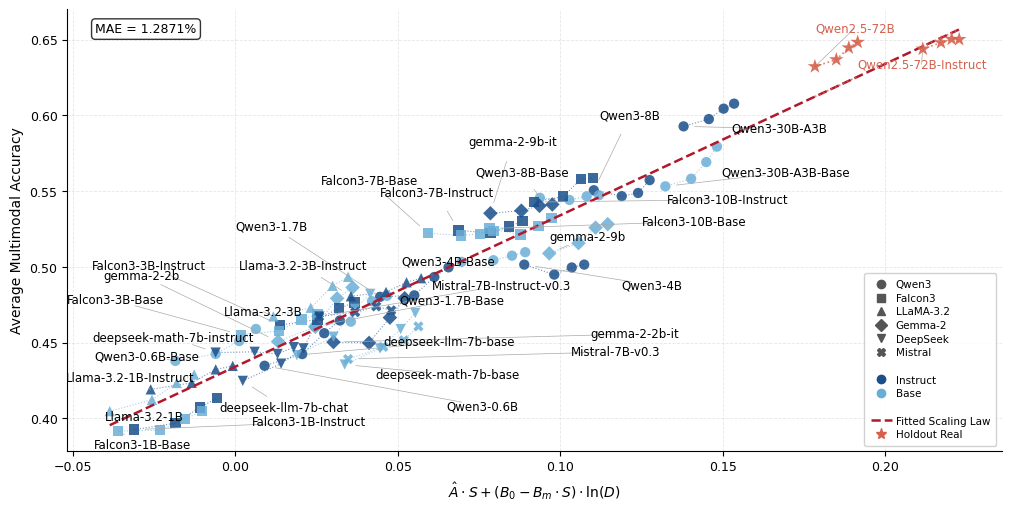

In [8]:
# ==========================================
# Block 8 - Redraw: Training + Holdout Predictions (real values with dashed line)
# ==========================================

# Create a new figure and axis
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), constrained_layout=True)

# ----------- Plot training set fitted points -----------
texts = []
all_scatter_x = []
all_scatter_y = []

for m_idx in range(n_train):
    fam = families[m_idx]
    mtype = model_types[m_idx]
    marker = MARKER_MAP[fam]
    color = COLOR_MAP[mtype]

    x_row = X_train[m_idx]
    y_row = Y_train[m_idx]
    valid = ~np.isnan(y_row)

    ax.plot(x_row[valid], y_row[valid],
            color=color, linewidth=0.8, linestyle=':', alpha=0.6, zorder=2)
    ax.scatter(x_row[valid], y_row[valid],
               marker=marker, color=color, s=MARKER_SIZE,
               alpha=0.85, edgecolors='none', zorder=3)

    all_scatter_x.extend(x_row[valid].tolist())
    all_scatter_y.extend(y_row[valid].tolist())

    first_valid = np.where(valid)[0]
    if len(first_valid) > 0:
        fx = x_row[first_valid[0]]
        fy = y_row[first_valid[0]]
        t = ax.text(fx, fy, model_names[m_idx],
                    fontsize=ANNOT_SIZE, color='black',
                    va='bottom', ha='left', zorder=5)
        texts.append(t)

# ----------- Holdout models (real scatter + dashed line, predicted curve) -----------
holdout_models = ["Qwen2.5-72B-Instruct", "Qwen2.5-72B"]

# Load full text_accuracy to get holdout rows
full_text_acc_df = pd.read_csv("eval_results/text_accuracy.csv")
full_text_acc_df.columns = full_text_acc_df.columns.str.strip()
holdout_text_acc_df = full_text_acc_df.tail(2)

# Transform to PC values using fitted PCA
holdout_pc_values = pca_analyzer.transform(holdout_text_acc_df.iloc[:, 1:])
holdout_pc_df = pd.DataFrame(holdout_pc_values, columns=pc_columns)
holdout_pc_df.insert(0, 'modelname', holdout_text_acc_df['model_name'].tolist())

# Load multimodal_accuracy for real accuracy values
multi_acc_full = pd.read_csv("eval_results/multimodal_accuracy.csv")
multi_acc_full.columns = multi_acc_full.columns.str.strip()

texts_72b = []
ho_xs = []
ho_ys = []

ho_y_pred_all = []
ho_y_real_all = []

for model in holdout_models:
    # Get PC vector and projection
    S_vec = holdout_pc_df.loc[holdout_pc_df['modelname'] == model, pc_name[:pc_needed]].values.flatten()
    S_val = np.dot(k_normalized, S_vec)

    # Get ckpt columns 3000~12000 only
    df_row = multi_acc_full[multi_acc_full['BaseModel'].str.endswith(model)].iloc[0]
    ckpt_cols = [c for c in multi_acc_full.columns if c.startswith("ckpt-")]
    ckpt_cols = [c for c in ckpt_cols if 3000 <= int(c.replace("ckpt-", "")) <= 12000]
    D_vals = [int(c.replace("ckpt-", "")) * 8192 * 512 / 1e9 for c in ckpt_cols]
    ln_D_vals = np.log(D_vals)

    # Predicted curve (for reference)
    Y_pred_curve = (A_true * S_val + (B0 - Bm_true * S_val) * ln_D_vals + P0)
    X_pred_curve = (A_true * S_val + (B0 - Bm_true * S_val) * ln_D_vals)
    # Real scatter values
    Y_real = []
    for c in ckpt_cols:
        val = df_row[c]
        if isinstance(val, str) and '%' in val:
            val = float(val.rstrip('%')) / 100
        Y_real.append(float(val))
    Y_real = np.array(Y_real)

    ho_y_pred_all.extend(Y_pred_curve.tolist())
    ho_y_real_all.extend(Y_real.tolist())
    
    # Plot predicted curve
    ax.plot(X_pred_curve, Y_pred_curve,
            color=COLOR_MAP['holdout_true'],
            linewidth=1.2, linestyle=':', alpha=0.8, zorder=4)

    # Plot real values with dashed line + scatter
    ax.plot(X_pred_curve, Y_real,
            color=COLOR_MAP['holdout_true'],
            linewidth=1.2, linestyle=':', alpha=0.8, zorder=4)
    ax.scatter(X_pred_curve, Y_real,
               marker=MARKER_MAP['Qwen2.5'],
               color=COLOR_MAP['holdout_true'],
               s=120, alpha=0.9,
               edgecolors='none', zorder=5)

    ho_xs.extend(X_pred_curve.tolist())
    ho_ys.extend(Y_real.tolist())

    offset_base = 0.025
    offset_chat = 0.01
    fy = Y_real[0] - offset_chat if 'Instruct' in model else Y_real[0] + offset_base
    x_offset = -0.02 if 'Instruct' in model else 0
    text_x = X_pred_curve[0] + x_offset
    t = ax.text(
        text_x, fy,
        model,
        fontsize=ANNOT_SIZE, color=COLOR_MAP['holdout_true'],
        va='center', ha='left', zorder=6,
    )
    texts_72b.append(t)

    fig.canvas.draw()
    bbox = t.get_window_extent(fig.canvas.renderer)
    bbox_data = Bbox(ax.transData.inverted().transform(bbox))
    arrow_end_x = (bbox_data.x0 + bbox_data.x1) / 2
    arrow_end_y = (bbox_data.y0 + bbox_data.y1) / 2

    ax.annotate(
        '',
        xy=(X_pred_curve[0], Y_real[0]),
        xytext=(arrow_end_x, arrow_end_y),
        arrowprops=dict(arrowstyle='-', color='#aaaaaa', lw=0.5, shrinkA=0, shrinkB=0)
    )

# ----------- Fitted scaling law line (extended range) -----------
all_X_values = np.concatenate([X_train.flatten(), np.array(ho_xs)])
all_Y_values = np.concatenate([Y_train.flatten(), np.array(ho_ys)])
valid_all = ~np.isnan(all_Y_values)

x_line = np.linspace(all_X_values[valid_all].min(), all_X_values[valid_all].max(), 200)
y_line = x_line + P0

ax.plot(x_line, y_line,
        color='#B2182B',
        linewidth=LINE_WIDTH,
        linestyle='--',
        label='Fitted Scaling Law',
        zorder=3)

# ----------- Adjust text to avoid overlap (training set only) -----------
adjust_text(
    texts,
    x=all_scatter_x + ho_xs, y=all_scatter_y + ho_ys, ax=ax,
    expand=(1.5, 1.6),
    arrowprops=dict(arrowstyle='-', color='#aaaaaa', lw=0.5, shrinkA=15, shrinkB=8),
    force_text=(0.8, 1.0),
    force_points=(0.6, 0.8),
    iter_lim=1000
)

# ----------- Legend -----------
shape_handles = [mlines.Line2D([], [], color='#555555', marker=MARKER_MAP[fam],
                                linestyle='None', markersize=MARKER_MS, label=fam)
                 for fam in unique_families]
color_handles = [
    mlines.Line2D([], [], color=COLOR_MAP['chat'], marker='o', linestyle='None',
                  markersize=MARKER_MS, label='Instruct'),
    mlines.Line2D([], [], color=COLOR_MAP['base'], marker='o', linestyle='None',
                  markersize=MARKER_MS, label='Base')
]
fit_handle = mlines.Line2D([], [], color='#B2182B', linewidth=LINE_WIDTH,
                           linestyle='--', label='Fitted Scaling Law')
pred_handle = mlines.Line2D([], [], color=COLOR_MAP['holdout_true'],
                            marker=MARKER_MAP['Qwen2.5'], linestyle='None',
                            markersize=MARKER_MS+2, label='Holdout Real')
separator = Patch(color='none', label='')

ax.legend(handles=(shape_handles + [separator] + color_handles + [separator, fit_handle, pred_handle]),
          fontsize=LEGEND_SIZE, framealpha=0.9, edgecolor='#cccccc',
          loc='lower right', borderaxespad=0.5, handletextpad=0.4,
          borderpad=0.6, labelspacing=0.35)

ax.text(0.03, 0.97, f'MAE = {mae_train*100:.4f}%',
        transform=ax.transAxes, fontsize=FONT_SIZE,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# ----------- Axis labels and style -----------
ax.set_xlabel(r'$\hat{A} \cdot S + (B_0 - B_m \cdot S) \cdot \ln(D)$', fontsize=LABEL_SIZE)
ax.set_ylabel('Average Multimodal Accuracy', fontsize=LABEL_SIZE)
ax.tick_params(labelsize=FONT_SIZE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3, linewidth=0.6)

fig.savefig("assets/main_pic_with_72B.pdf", dpi=300, bbox_inches='tight')
plt.show()